# 02 · Construcción de variables (sin fuga de datos)

Cada variable usa solo información disponible en el instante de la compra. Las de historial (vendedor y ruta) son las más delicadas, porque es fácil colarles información del futuro sin darse cuenta.

La lógica está en `src/features.py`. En este notebook construyo las variables, verifico que no haya fuga de datos y reviso cuánta señal aporta cada una.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from features import CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, build_features, load_model_base
from plot_style import BLUE, INK_2, ORANGE, apply_style

apply_style()
FIG_DIR = "../reports/figures"

# Inicio del periodo de prueba. Los priors de suavizado se calculan
# solo con lo que se conocía antes de esta fecha.
TEST_START = pd.Timestamp("2018-04-01")

df = load_model_base("../data/processed/model_base.csv")
X = build_features(df, cutoff=TEST_START)
print(f"{len(X):,} pedidos · {len(FEATURES)} variables "
      f"({len(NUMERIC_FEATURES)} numéricas, {len(CATEGORICAL_FEATURES)} categóricas)")

97,300 pedidos · 26 variables (22 numéricas, 4 categóricas)


## 1. ¿Cuándo se conoce el resultado de un pedido?

Es la pieza central para evitar la fuga. El historial de un vendedor no puede incluir pedidos cuyo resultado todavía no se conocía al momento de la compra.

| Resultado | Se conoce cuando... |
|---|---|
| A tiempo | se entrega (`delivered_ts`) |
| Tarde o no entregado | termina el día prometido (00:00 del día siguiente a `estimated_date`) |

Un pedido tardío "se sabe" tarde al vencer la promesa, aunque llegue semanas después.

In [2]:
X[["order_id", "purchase_ts", "estimated_date", "delivered_ts", "is_late", "outcome_known_ts"]].sample(5, random_state=1)

,order_id,purchase_ts,estimated_date,delivered_ts,is_late,outcome_known_ts
6716,5cb4fa11d9f8e1c1dbff3ac693ddcbf5,2017-04-23 20:56:12,2017-05-18,2017-05-11 16:12:21,0,2017-05-11 16:12:21
9943,9add7e9338f3b8cac642ce405bb64655,2017-05-22 19:49:13,2017-06-21,2017-06-09 14:13:44,0,2017-06-09 14:13:44
85016,311f11836437bf8950d50701fb64fcbf,2018-07-02 21:45:09,2018-07-30,2018-07-10 17:51:24,0,2018-07-10 17:51:24
49473,28e9ee43938891c706c6c9e8ce21d0ec,2018-01-24 14:28:01,2018-02-16,2018-01-29 21:34:01,0,2018-01-29 21:34:01
8318,ac0bd3bcb4062dc7bfd025109df9e6e4,2017-05-09 14:58:25,2017-06-08,2017-05-25 10:43:47,0,2017-05-25 10:43:47


## 2. Auditoría de fuga: recalcular el historial por fuerza bruta

Para 500 pedidos al azar recalculo el historial del vendedor de la forma más ingenua posible: filtrando todos sus pedidos con resultado conocido antes de la compra.

Si la versión eficiente (`merge_asof`) coincide en todos los casos, no está usando información futura.

In [3]:
PRIOR = 20
global_rate = X.loc[X.outcome_known_ts < TEST_START, "is_late"].mean()

rng = np.random.default_rng(42)
mismatches = 0
for i in rng.choice(len(X), size=500, replace=False):
    row = X.iloc[i]
    known = X[(X.main_seller_id == row.main_seller_id) & (X.outcome_known_ts < row.purchase_ts)]
    expected_rate = (known.is_late.sum() + PRIOR * global_rate) / (len(known) + PRIOR)
    if abs(expected_rate - row.seller_late_rate_hist) > 1e-9 or len(known) != row.seller_known_orders:
        mismatches += 1
print(f"Discrepancias en 500 pedidos: {mismatches}")

# Segunda verificación: ningún pedido se ve a sí mismo en su historial
self_seen = (X.outcome_known_ts < X.purchase_ts).sum()
print(f"Pedidos cuyo propio resultado se conocía antes de comprarse: {self_seen}")

Discrepancias en 500 pedidos: 0
Pedidos cuyo propio resultado se conocía antes de comprarse: 0


Otras medidas contra la fuga:

- Variables excluidas: la reseña, las fechas de aprobación y envío y cualquier dato posterior a la compra nunca entran como variables.
- Priors de suavizado: la tasa global de retraso y los días promedio se calculan solo con información anterior al periodo evaluado (`cutoff`).
- Codificación: los escaladores e imputadores se ajustan dentro de un `Pipeline`, así que solo ven datos de entrenamiento (notebook 03).

## 3. Variables descartadas por cambio de régimen

En pruebas preliminares el modelo usaba el mes de compra, el número absoluto de pedidos de la plataforma y los conteos absolutos de cada vendedor para memorizar la época del entrenamiento. Las tres variables crecen o cambian con el tiempo, así que en un periodo nuevo apuntan a lo que ya no aplica.

Las reemplacé por versiones relativas: `platform_load_ratio` compara la última semana contra el promedio de las últimas cuatro.

## 4. ¿Cuánta señal tiene cada variable por sí sola?

AUC de cada variable numérica, usada directamente como puntaje, en el periodo de entrenamiento:
- 0.5 significa que no separa los pedidos tardíos de los puntuales.
- Valores menores a 0.5 indican que a mayor valor, menor riesgo.

In [4]:
train = X[X.outcome_known_ts < TEST_START]
rows = []
for col in NUMERIC_FEATURES:
    s = train[col].fillna(train[col].median())
    auc = roc_auc_score(train.is_late, s)
    rows.append({"variable": col, "auc": round(auc, 3), "separación": round(abs(auc - 0.5), 3)})
signal = pd.DataFrame(rows).sort_values("separación", ascending=False).reset_index(drop=True)
signal.head(12)

,variable,auc,separación
0,promise_ratio,0.349,0.151
1,route_hist_days,0.645,0.145
2,route_late_rate_hist,0.629,0.129
3,promise_buffer_route,0.388,0.112
4,max_distance_km,0.573,0.073
5,seller_hist_days,0.573,0.073
6,freight_value,0.569,0.069
7,same_state,0.433,0.067
8,platform_load_ratio,0.561,0.061
9,seller_late_rate_hist,0.535,0.035


Las variables con más señal son dos:
- Colchón del plazo (`promise_ratio`): días prometidos entre los días que tardó la ruta en los últimos 90 días. Es la más fuerte de todas.
- Historial de la ruta: cuántos días suele tardar (`route_hist_days`) y con qué frecuencia llega tarde (`route_late_rate_hist`).

La distancia, el flete y la carga de la plataforma aportan menos. Me sorprendió que el historial del vendedor aporte tan poco por sí solo.

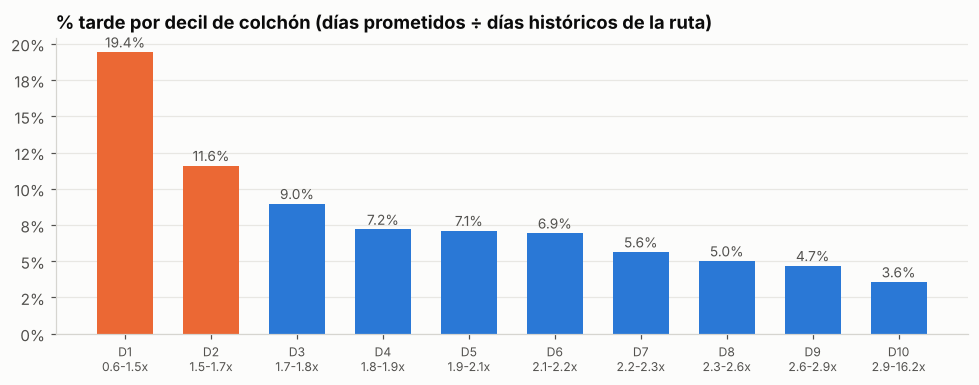

,late_pct,ratio_min,ratio_max
ratio_decile,,,
1,19.43,0.61,1.45
2,11.60,1.45,1.66
3,8.97,1.66,1.81
4,7.20,1.81,1.93
5,7.12,1.93,2.05
6,6.94,2.05,2.18
7,5.64,2.18,2.34
8,5.02,2.34,2.55
9,4.70,2.55,2.91


In [5]:
train = train.assign(ratio_decile=pd.qcut(train.promise_ratio, 10, labels=False) + 1)
by_decile = train.groupby("ratio_decile").agg(
    late_pct=("is_late", lambda s: 100 * s.mean()),
    ratio_min=("promise_ratio", "min"),
    ratio_max=("promise_ratio", "max"),
)

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [ORANGE if d <= 2 else BLUE for d in by_decile.index]
ax.bar(by_decile.index, by_decile.late_pct, color=colors, width=0.65)
for d, v in by_decile.late_pct.items():
    ax.annotate(f"{v:.1f}%", (d, v), textcoords="offset points", xytext=(0, 3),
                ha="center", fontsize=9, color=INK_2)
ax.set_xticks(by_decile.index)
ax.set_xticklabels([f"D{d}\n{r.ratio_min:.1f}-{r.ratio_max:.1f}x" for d, r in by_decile.iterrows()], fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("% tarde por decil de colchón (días prometidos ÷ días históricos de la ruta)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/03_late_by_promise_ratio_decile.png", dpi=160)
by_decile.round(2)

La relación es clara y monótona:
- Colchón corto (D1): cuando Olist promete menos de ~1.45 veces lo que tardó la ruta en los últimos 90 días, 19% de los pedidos llegan tarde.
- Colchón amplio (D7-D10): cuando promete más de ~2.2 veces, el retraso baja a entre 3.6% y 5.6%.

In [6]:
X.to_csv("../data/processed/features.csv", index=False)
print("Variables guardadas en data/processed/features.csv")

Variables guardadas en data/processed/features.csv
